# Δα biology across datasets

*Companion to `03_alpha_master.ipynb`. The master notebook defended
the architecture that emits Δα; this notebook asks **which kinds of
genes Δα singles out** on each dataset, and whether the same
biological categories emerge as conserved/divergent across tissues
and species sets.*

Δα = α − conservation_prior is the GIN's *learned* per-gene
correction. Positive Δα = "more conserved than the protein-sequence
prior alone would predict" (FQR-driven, iter81b unrectified-S_g
mechanism). Negative Δα = "less conserved than the prior" (residual +
L_recon force).

The notebook follows three movements:

1. **§A — what biology is in each dataset's Δα?** Per-dataset
   boxplots of Δα by gene category, plus Fisher enrichment of each
   category in the top-10 % vs bottom-10 % Δα tails (with
   Bonferroni correction).
2. **§B — are the category signatures consistent across datasets?**
   Two cross-dataset heatmaps — mean Δα per (category × dataset)
   and Fisher log₂-OR per (category × dataset) — let the reader
   see at a glance which categories are reproducibly pushed up or
   down across the registry.
3. **§C — gene-level lists.** Top-30 most-positive and
   most-negative Δα genes per dataset, with category annotation,
   printed and saved as CSV under each run-dir.

All visual conventions inherit from
[`_figure_design.py`](_figure_design.py): no grids, no
top/right spines, no titles, single typeface, vector PDF output.
Diverging quantities (mean Δα, log₂ odds ratio) use ``RdBu_r``
centered on 0 — the only color admitted beyond the species
palette.


## §0.1 — Imports and design system

Same setup as `03_alpha_master.ipynb`. The extended gene-category
vocabulary is in [`_gene_categories.py`](_gene_categories.py).


In [1]:
import json
import sys
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

NB_DIR = Path.cwd() if (Path.cwd() / "_figure_design.py").exists() \
         else Path("/Users/kemalinecik/git_nosync/master_chimera/chimera/notebooks")
if str(NB_DIR) not in sys.path:
    sys.path.insert(0, str(NB_DIR))

import _figure_design as fd
import _gene_categories as gc
import _paper_utils as pu

fd.apply_design()


## §0.2 — Dataset registry (single-seed per registry row)

Seven distinct (tissue × species set) combinations from
`chimera/training/workflow-best.md`. We use seed 42 for every row
(cross-seed Δα reproducibility was already addressed in
`03_alpha_master.ipynb` §B.1); this notebook is about **biology
across datasets**, not seed stability.


In [2]:
REPO_ROOT = Path("/Users/kemalinecik/git_nosync/master_chimera/chimera")
RUNS_ROOT = REPO_ROOT / "training" / "runs"
DATA_ROOT = REPO_ROOT / "data" / "processed"

FIG_DIR = fd.set_figure_dir(NB_DIR / "figures" / "alpha_biology")
print(f"figures will be written to: {FIG_DIR}")

# 7 datasets, single-seed (s42) per row.
DATASETS = {
    "panc_hmonkey":  {"name": "iter90-150ep-s42",
                      "adata": "camex_human_monkey.h5ad",
                      "tissue": "pancreas", "label": "panc H+Monkey"},
    "panc_hmouse":   {"name": "xds-hmouse-iter90-150ep-s42",
                      "adata": "camex_human_mouse.h5ad",
                      "tissue": "pancreas", "label": "panc H+Mouse"},
    "panc_hzeb":     {"name": "xds-hzeb-iter85-s42",
                      "adata": "camex_human_zebrafish.h5ad",
                      "tissue": "pancreas", "label": "panc H+Zeb"},
    "panc_4sp":      {"name": "xds-4sp-iter101-adv200-mmd100-fb10-200ep-s42",
                      "adata": "camex_pancreas_unified.h5ad",
                      "tissue": "pancreas", "label": "panc 4-sp"},
    "test_hmac":     {"name": "testis-hmac-iter109-pclamp085-200ep-s42",
                      "adata": "camex_testis_human_macaque.h5ad",
                      "tissue": "testis",   "label": "test H+Mac"},
    "test_hmouse":   {"name": "testis-hmouse-iter111-pclamp-coc-200ep-s42",
                      "adata": "camex_testis_human_mouse.h5ad",
                      "tissue": "testis",   "label": "test H+Mouse"},
    "test_3sp":      {"name": "testis-unified-iter115-pclamp-coc-100ep-s42",
                      "adata": "camex_testis_unified.h5ad",
                      "tissue": "testis",   "label": "test 3-sp"},
}
# Display order: pancreas first, by divergence; then testis.
DATASET_ORDER = ["panc_hmonkey", "panc_hmouse", "panc_hzeb", "panc_4sp",
                 "test_hmac", "test_hmouse", "test_3sp"]

for k in DATASETS:
    d = RUNS_ROOT / DATASETS[k]["name"]
    assert (d / "final_state.npz").exists(), f"missing final_state for {k}: {d}"
print(f"registry: {len(DATASETS)} datasets, all final_state.npz present.")


figures will be written to: /Users/kemalinecik/git_nosync/master_chimera/chimera/notebooks/figures/alpha_biology
registry: 7 datasets, all final_state.npz present.


## §0.3 — Load every dataset's gene table

For each dataset we build a tidy DataFrame with one row per gene:

- `var_name` (the model's `ortho_X` ID)
- `symbol` (human ortholog gene symbol from `data/processed/ortholog_table.csv`)
- `category` (extended category from `_gene_categories.classify_extended`)
- `prior`, `alpha`, `delta_alpha`, `correction`, `S_g_ema`,
  `residual_mean_abs`, `residual_rms` (per-gene scalars from
  `final_state.npz`)
- `dataset` (the registry key)

Every downstream cell concatenates these tables and works in long
format.


In [3]:
_CACHE: dict[str, pd.DataFrame] = {}

def load_gene_table(key: str) -> pd.DataFrame:
    if key in _CACHE:
        return _CACHE[key]
    info = DATASETS[key]
    rundir = RUNS_ROOT / info["name"]
    fs = dict(np.load(rundir / "final_state.npz", allow_pickle=False))

    # Var names from the AnnData (ortho_X) — cheap, backed read.
    a = ad.read_h5ad(DATA_ROOT / info["adata"], backed="r")
    var_names = np.asarray(a.var_names)
    a.file.close()
    assert len(var_names) == len(fs["alpha"]), (
        f"{key}: adata.n_vars={len(var_names)} vs alpha.shape={len(fs['alpha'])}"
    )

    # Map ortho_X -> human gene symbol via the ortholog table
    sym = pu.annotate_genes_with_names(var_names)
    cat_df = gc.annotate_extended(var_names, sym)

    df = pd.DataFrame({
        "var_name":    var_names,
        "symbol":      cat_df["symbol"].values,
        "category":    cat_df["category"].values,
        "prior":       fs["prior"],
        "alpha":       fs["alpha"],
        "delta_alpha": fs["alpha"] - fs["prior"],
        "correction":  fs["correction"],
        "S_g_ema":     fs["S_g_ema"],
        "residual_mean_abs": fs["residual_mean_abs"],
        "residual_rms":      fs["residual_rms"],
        "dataset":     key,
    })
    _CACHE[key] = df
    return df


GENE_TABLES = {k: load_gene_table(k) for k in DATASET_ORDER}
LONG = pd.concat(GENE_TABLES.values(), ignore_index=True)
print(f"long table: {len(LONG):,} (gene, dataset) rows")
print(f"per-dataset gene counts:")
for k in DATASET_ORDER:
    print(f"  {DATASETS[k]['label']:18s} {len(GENE_TABLES[k]):>6d} genes")


long table: 78,667 (gene, dataset) rows
per-dataset gene counts:
  panc H+Monkey        8430 genes
  panc H+Mouse         8257 genes
  panc H+Zeb           7998 genes
  panc 4-sp            8879 genes
  test H+Mac          14640 genes
  test H+Mouse        14731 genes
  test 3-sp           15732 genes


# §A — Per-dataset Δα biology

First a sanity check: how many genes does each category cover in
each dataset? Categories below ~5 genes give noisy boxplots and
unreliable Fisher tests, so we'll suppress them in the per-dataset
figures. The coverage heatmap is the diagnostic.


## §A.0 — Category gene-coverage heatmap

Rows = categories, columns = datasets, cell value = number of
genes in the category. Categories with < 5 genes in a given
dataset are shown in pale gray; those with ≥ 5 are admissible
for that dataset's enrichment tests.


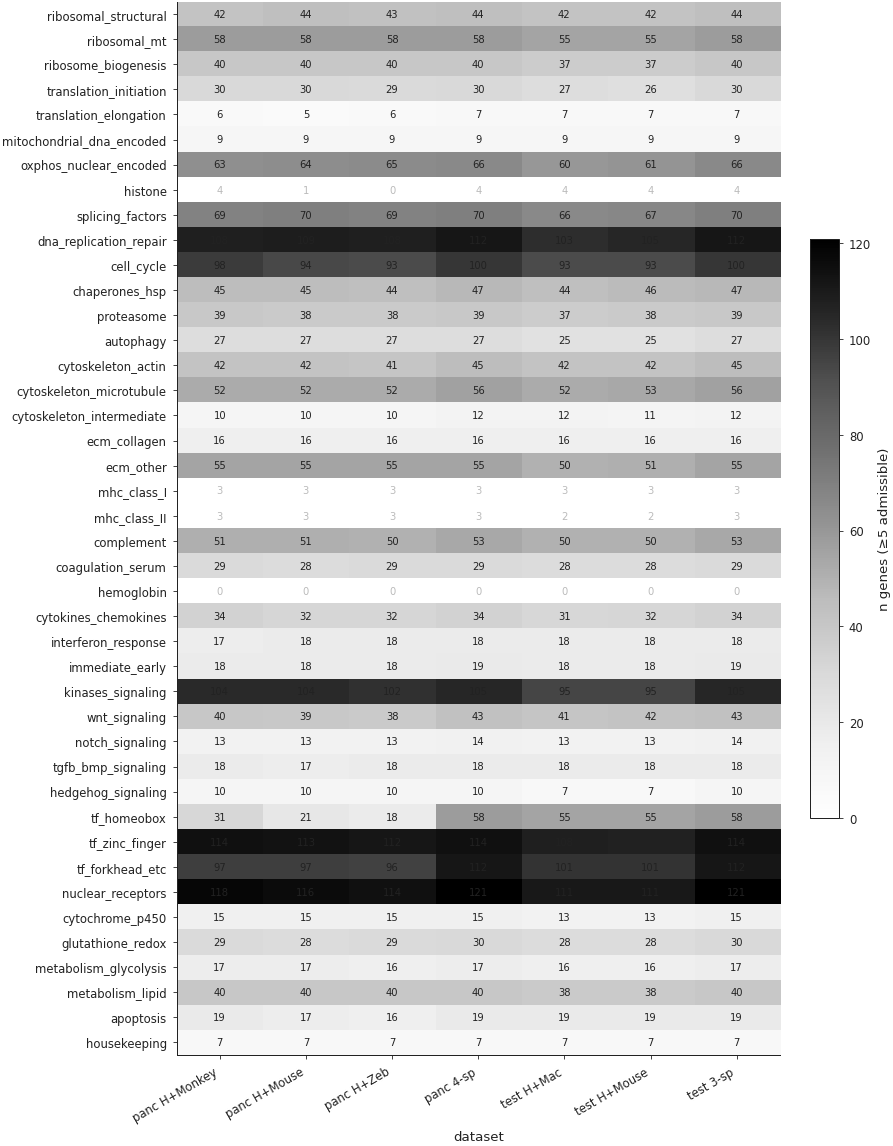

In [4]:
cats_admissible = [c for c in gc.CATEGORY_ORDER_EXTENDED if c != "other"]

coverage = pd.DataFrame(0, index=cats_admissible, columns=DATASET_ORDER, dtype=int)
for k in DATASET_ORDER:
    vc = GENE_TABLES[k]["category"].value_counts()
    for c in cats_admissible:
        coverage.loc[c, k] = int(vc.get(c, 0))

fig, ax = plt.subplots(figsize=(7.5, 0.20 * len(cats_admissible) + 1.2),
                       layout="constrained")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)

# Mask cells below threshold so they appear pale.
threshold = 5
masked = np.where(coverage.values >= threshold, coverage.values, np.nan)
im = ax.imshow(masked, aspect="auto", cmap="Greys",
               vmin=0, vmax=np.nanmax(masked) if np.isfinite(masked).any() else 1)
# Annotate every cell with the count
for i, c in enumerate(coverage.index):
    for j, k in enumerate(coverage.columns):
        v = coverage.iloc[i, j]
        ax.text(j, i, f"{v}", ha="center", va="center",
                fontsize=6,
                color="#222222" if v >= threshold else "#bbbbbb")
ax.set_xticks(range(len(DATASET_ORDER)))
ax.set_xticklabels([DATASETS[k]["label"] for k in DATASET_ORDER],
                   rotation=30, ha="right", fontsize=7)
ax.set_yticks(range(len(cats_admissible)))
ax.set_yticklabels(cats_admissible, fontsize=7)
ax.set_xlabel("dataset")
fig.colorbar(im, ax=ax, label="n genes (≥5 admissible)", shrink=0.55)
fd.save_figure(fig, "A0_category_coverage_heatmap")
plt.show()


*Read:* most categories cover ≥ 5 genes on every dataset.
Categories that are sparse on smaller datasets (e.g. *cytochrome
p450* and *cytokines* on testis pancreas-side) will be shown in
pale and excluded from per-dataset Fisher tests, but they remain
in the cross-dataset signature heatmap (§B) where the
cross-dataset average gives them more statistical power.


## §A.1 — Δα distribution by category, per dataset

Seven single-panel boxplot figures (one per dataset), one
box per category. Categories ordered by **median Δα ascending**
within each panel — so the leftmost categories are the
most-pushed-down (divergent) and the rightmost are the
most-pushed-up (FQR-conserved). A horizontal dashed line at
Δα = 0 marks the prior reference.

The same Δα axis range (`fd.DELTA_ALPHA_RANGE`) is enforced on
every panel so a reader can compare absolute magnitudes across
datasets at a glance — testis panels will look "small" relative
to pancreas panels because testis Δα.σ is structurally narrower
(prior clamp at 0.85), and that comparison is the entire point
of using shared axes.


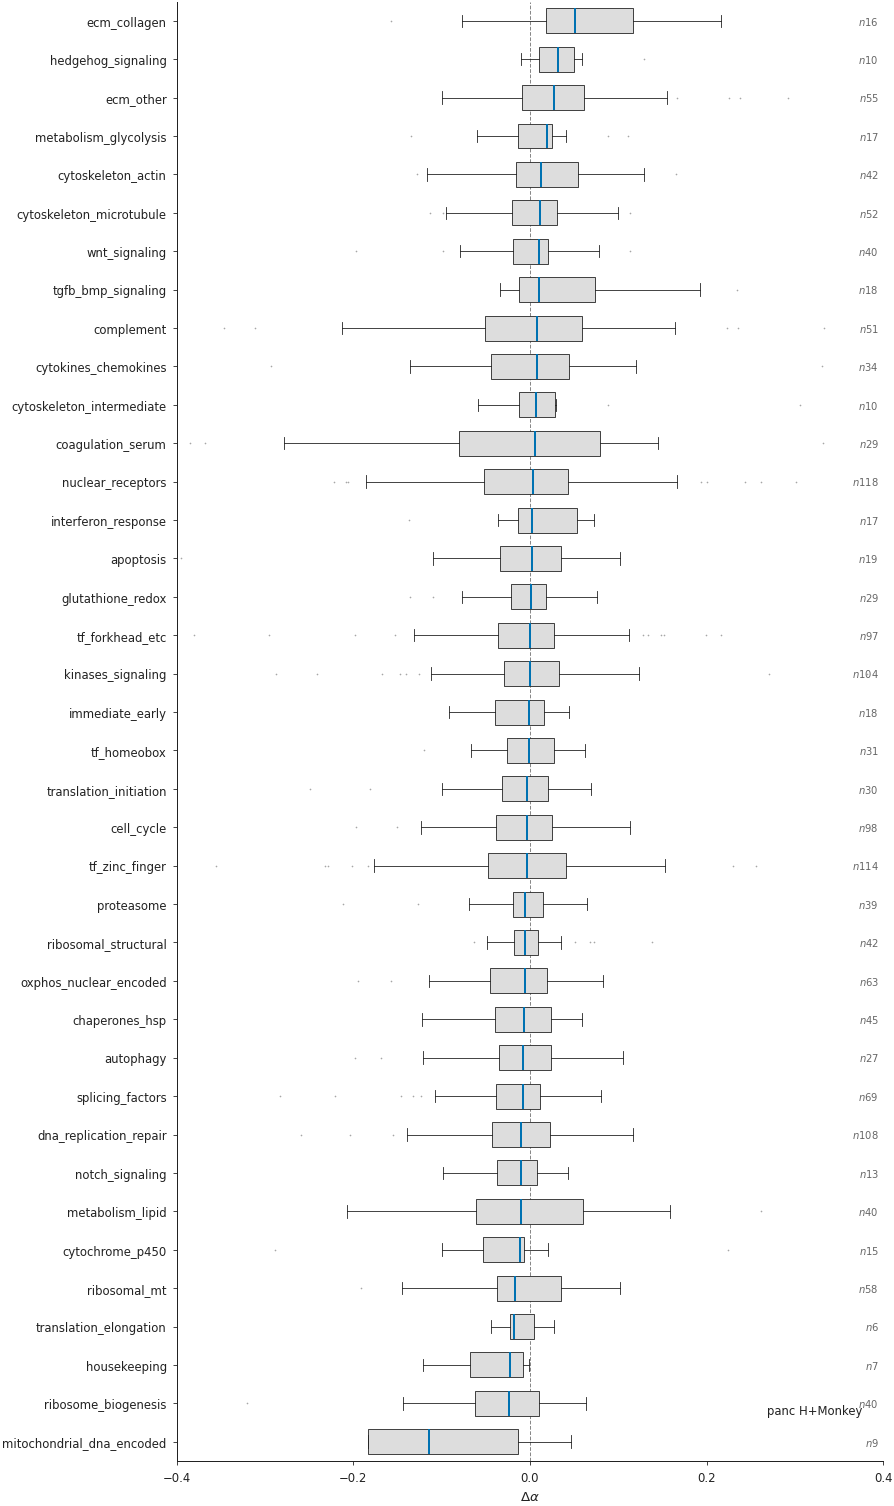

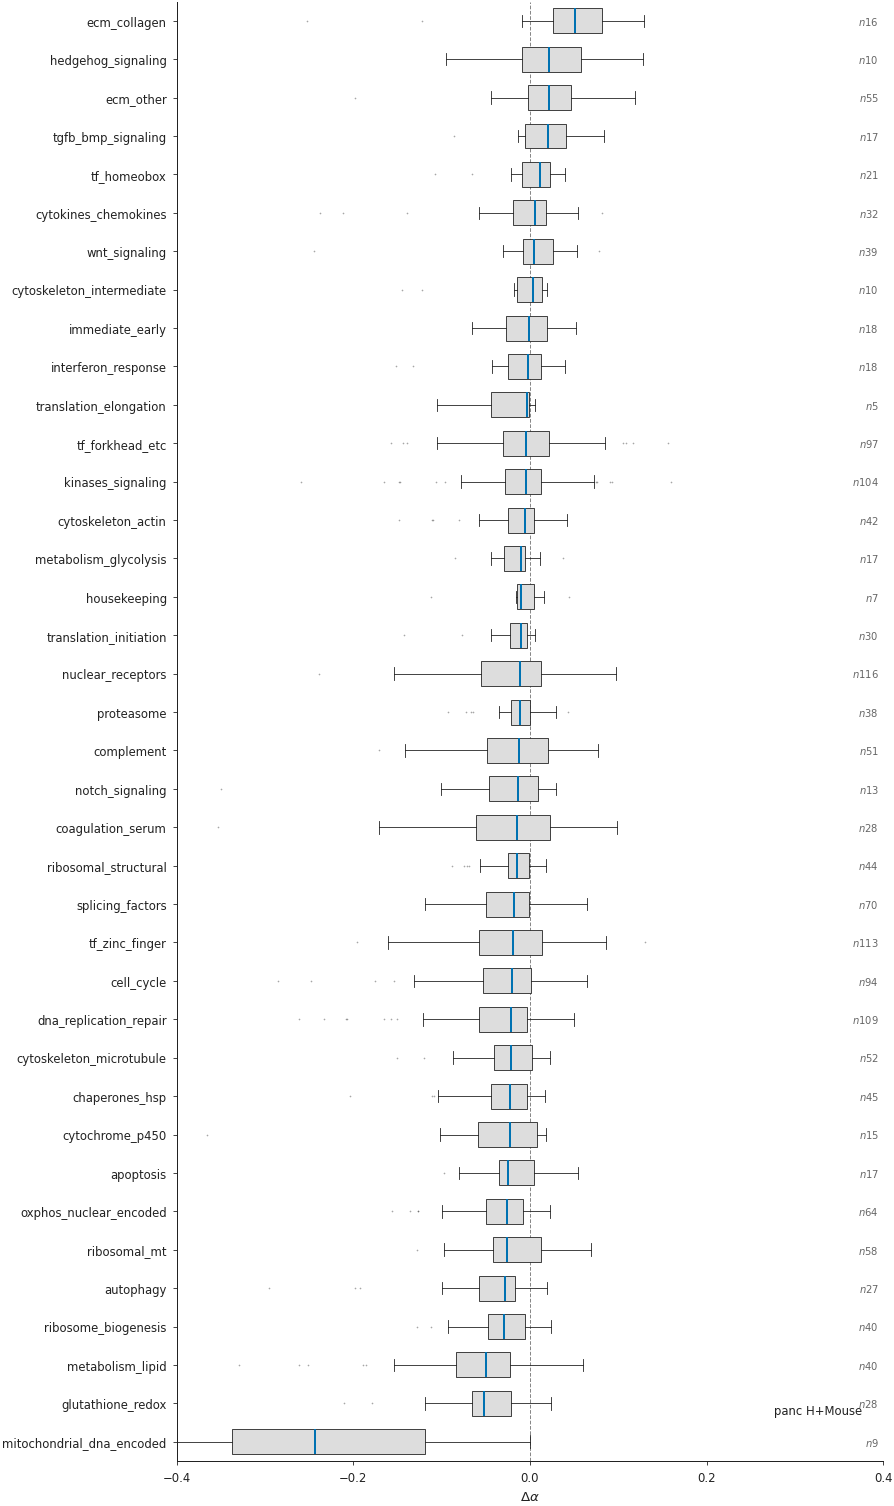

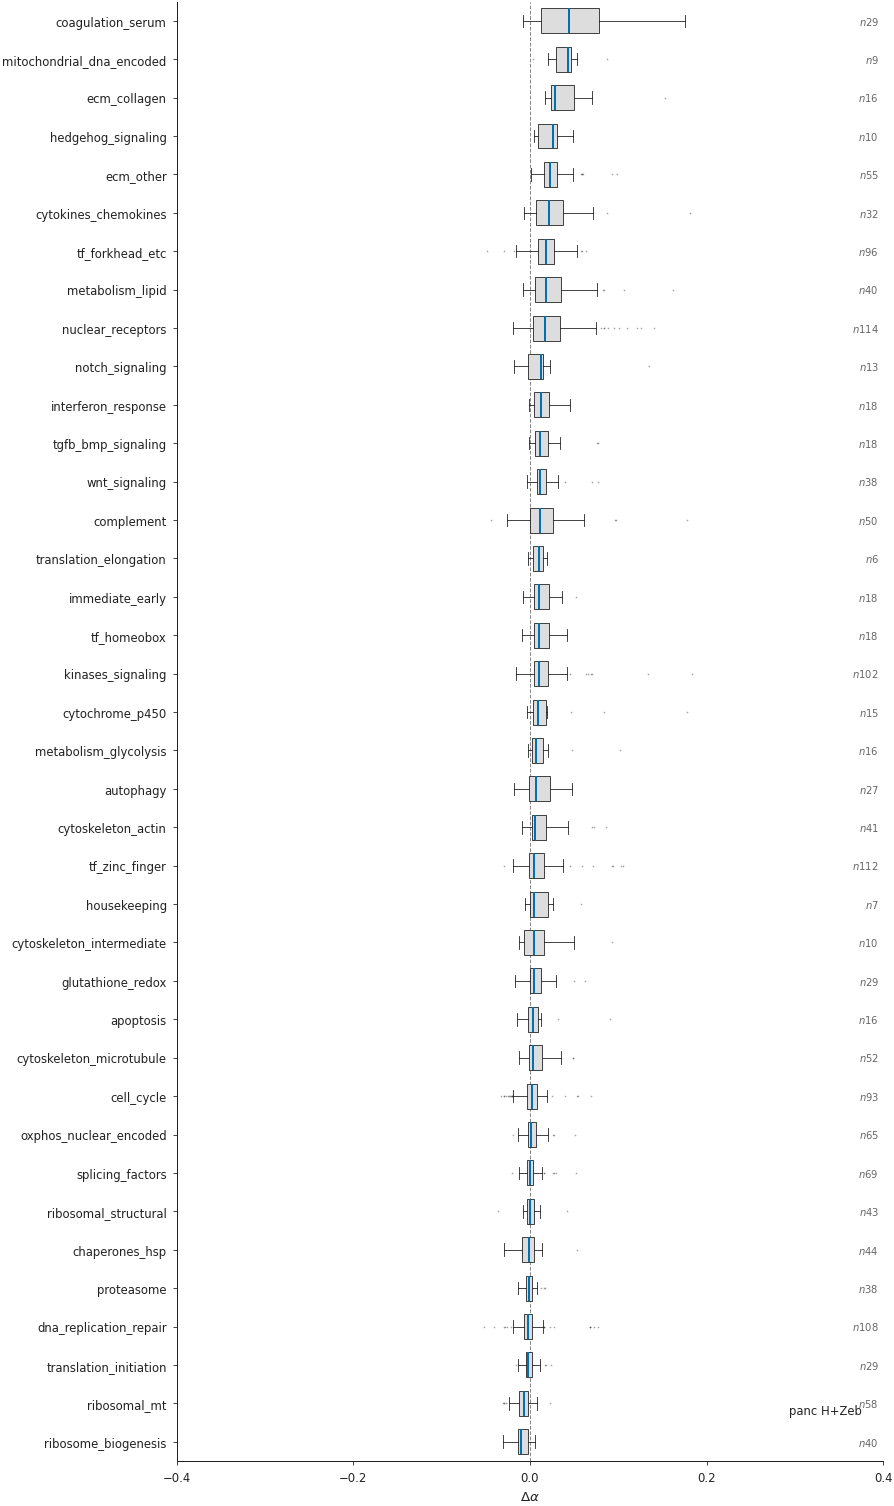

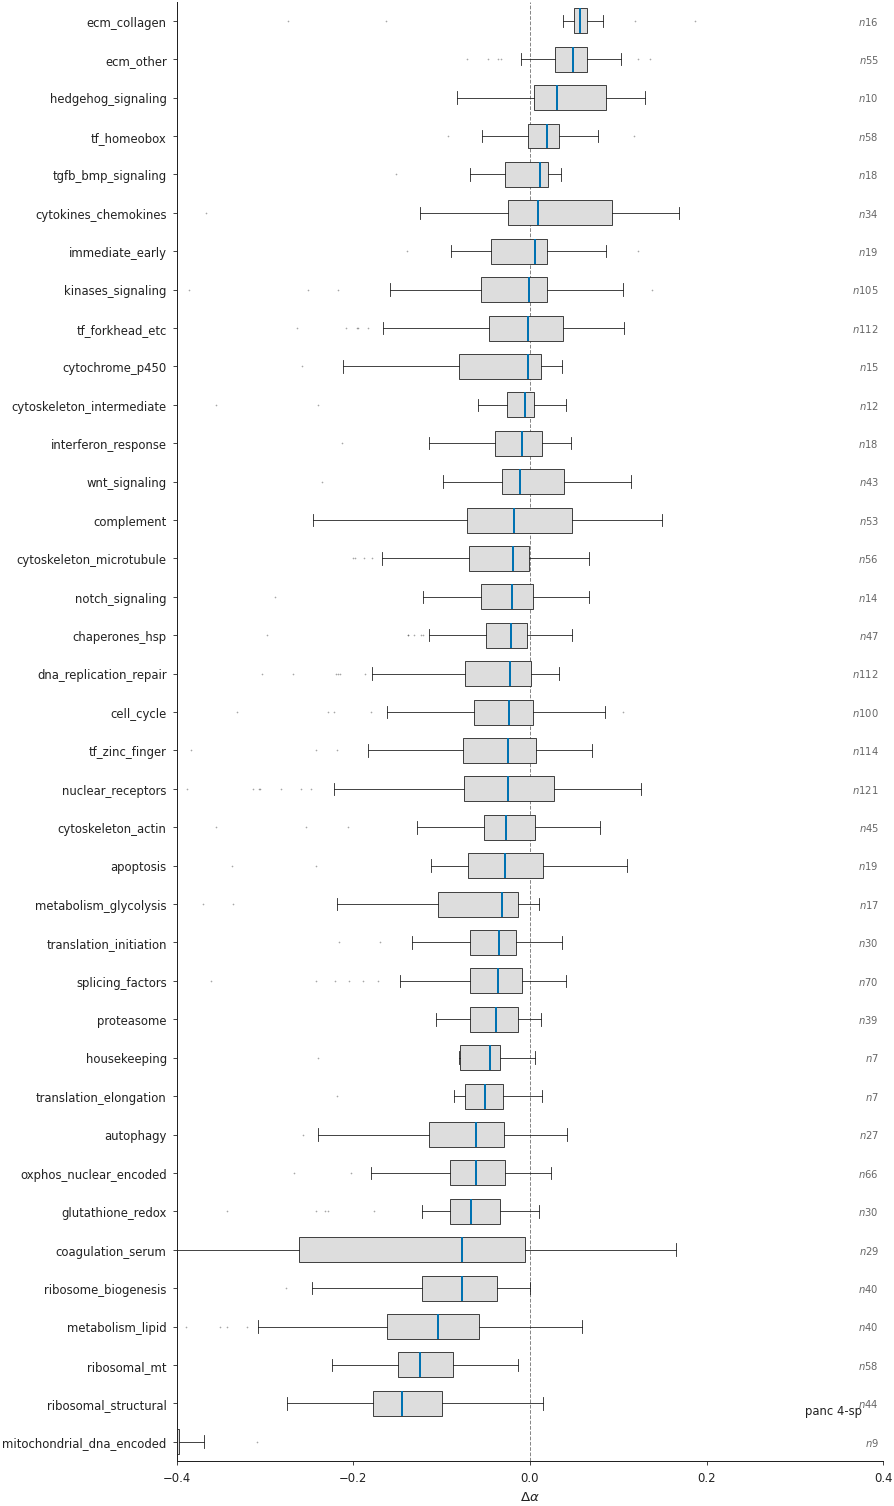

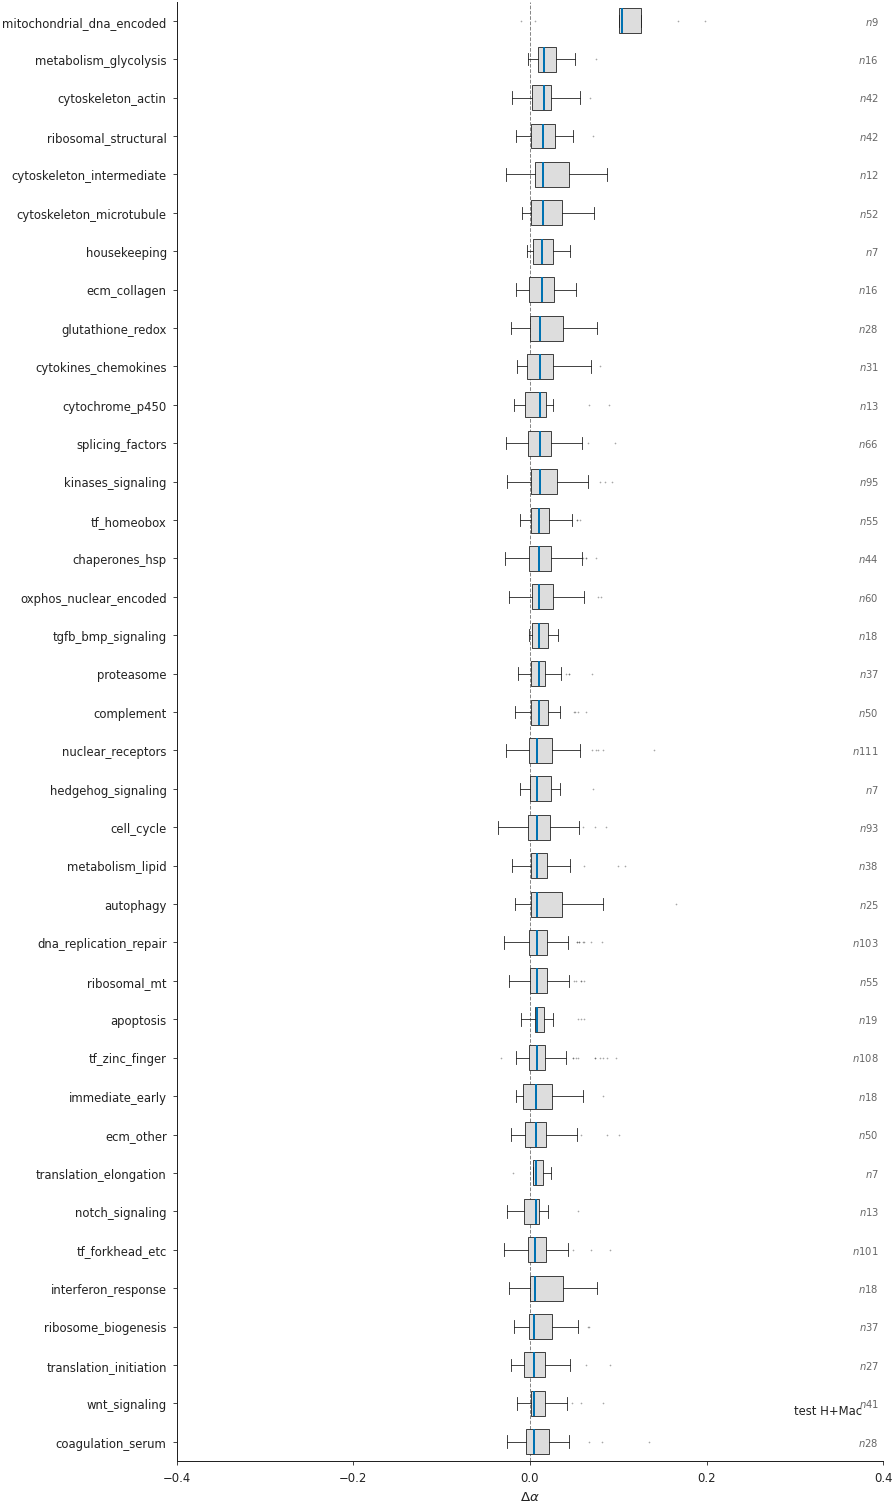

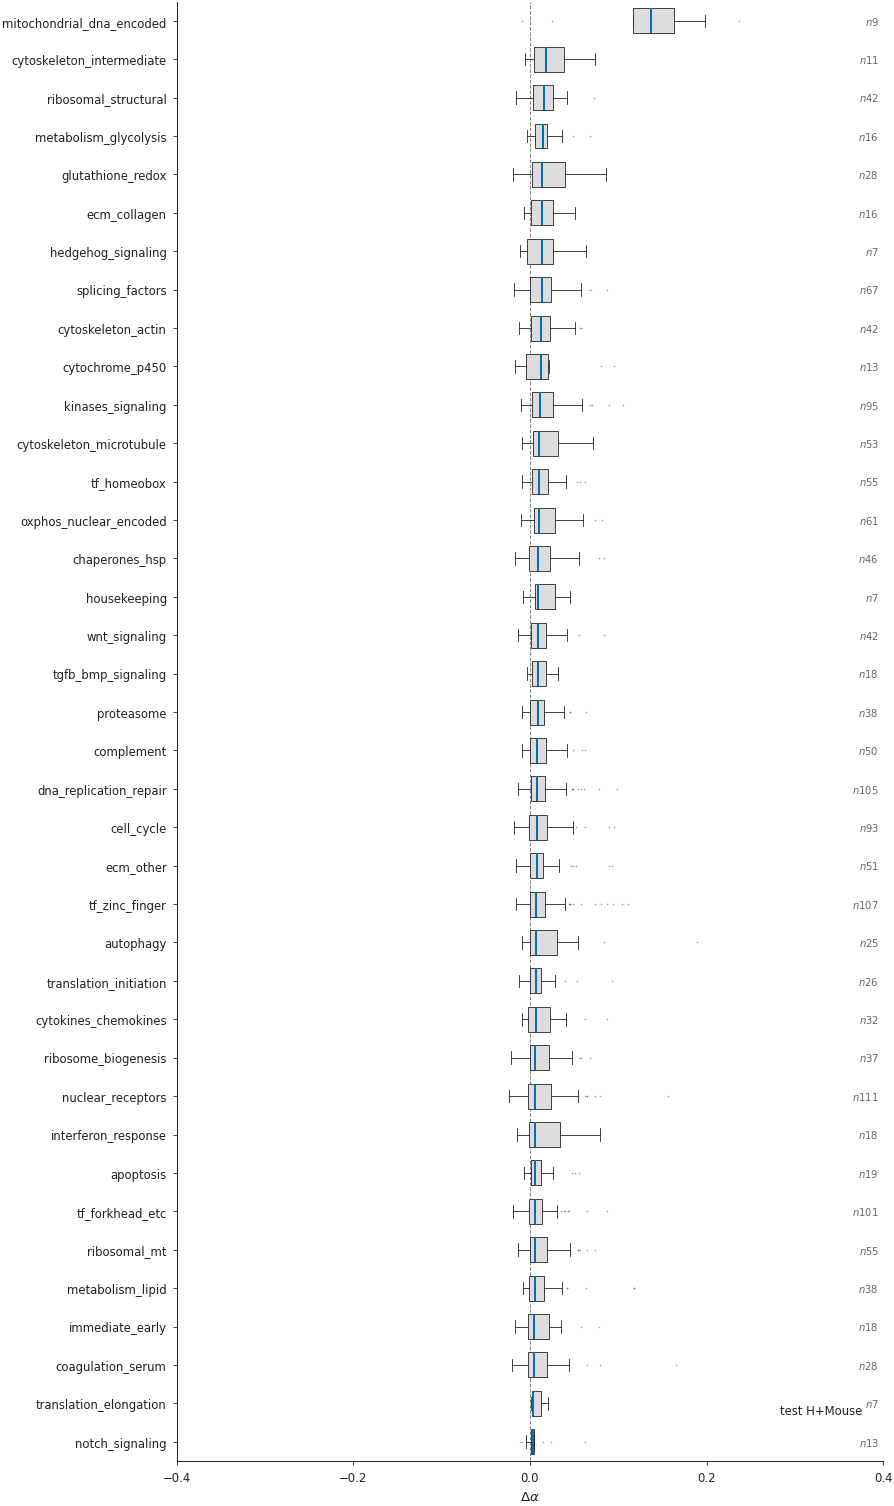

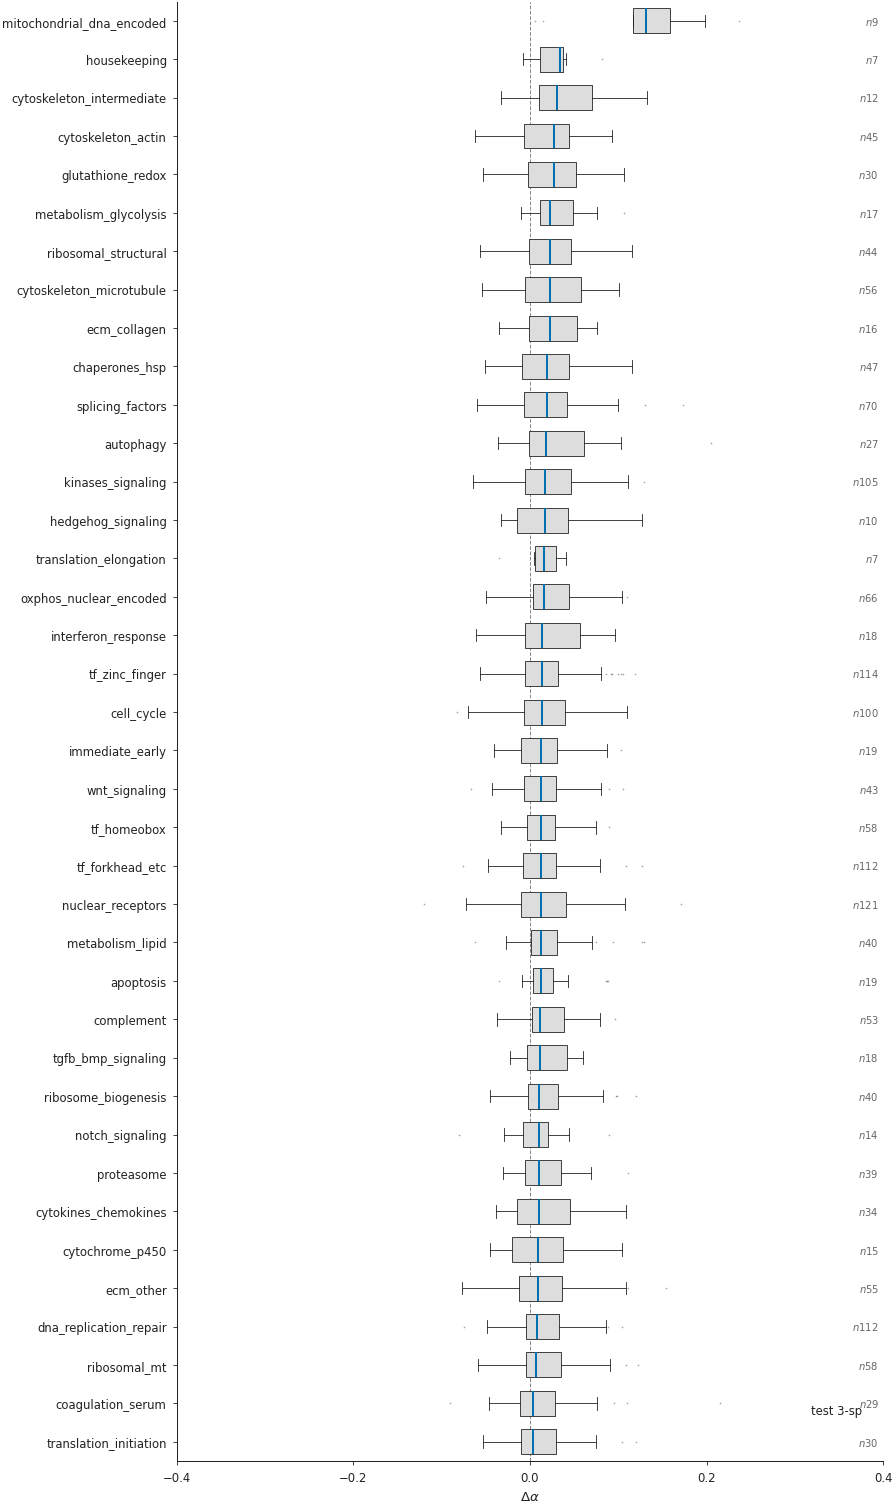

In [5]:
MIN_GENES_PER_BOX = 5

def plot_boxes_for_dataset(key: str, save_name: str):
    df = GENE_TABLES[key]
    # Drop "other"; only keep categories with enough genes
    present = (df.groupby("category", observed=True).size()
                 .loc[lambda s: s >= MIN_GENES_PER_BOX]
                 .index.tolist())
    present = [c for c in cats_admissible if c in present]
    sub = df[df["category"].isin(present)].copy()
    # Order by ascending median Δα
    med = sub.groupby("category", observed=True)["delta_alpha"].median()
    order = med.sort_values().index.tolist()
    sub["category"] = pd.Categorical(sub["category"], categories=order)

    h = 0.30 * len(order) + 1.2
    fig, ax = plt.subplots(figsize=(7.5, h), layout="constrained")
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.grid(False)

    # Build per-category arrays for matplotlib boxplot (no seaborn dependency)
    data = [sub.loc[sub["category"] == c, "delta_alpha"].values for c in order]
    bp = ax.boxplot(
        data, vert=False, positions=range(len(order)),
        widths=0.65, patch_artist=True,
        medianprops=dict(color="#0072B2", linewidth=1.2),
        boxprops=dict(facecolor="#dddddd", edgecolor="#222222", linewidth=0.5),
        whiskerprops=dict(color="#222222", linewidth=0.5),
        capprops=dict(color="#222222", linewidth=0.5),
        flierprops=dict(marker="o", markersize=1.0, markerfacecolor="#222222",
                        markeredgecolor="none", alpha=0.4),
    )
    # Annotate gene counts at right edge
    for i, c in enumerate(order):
        n = (sub["category"] == c).sum()
        ax.text(fd.DELTA_ALPHA_RANGE[1] - 0.005, i,
                f"$n${n}", ha="right", va="center",
                fontsize=6, color="#666666")
    ax.axvline(0, color="#888888", linewidth=0.6, linestyle="--", zorder=0)
    ax.set_xlim(*fd.DELTA_ALPHA_RANGE)
    ax.set_xticks(list(fd.DELTA_ALPHA_TICKS))
    ax.set_xlabel(fd.LABEL["delta_alpha"])
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(order, fontsize=7)
    fd.annotate_stat(ax, DATASETS[key]["label"], "lower right")
    fd.save_figure(fig, save_name)
    plt.show()


for k in DATASET_ORDER:
    plot_boxes_for_dataset(k, f"A1_delta_alpha_by_category__{k}")


*Read:* expect the *direction* of category-level Δα to match
biological intuition where the architecture has signal —
e.g. ribosomal / OXPHOS / housekeeping near or above zero
(sequence-conserved AND expression-conserved across species);
immediate-early / cytokines below zero on close-pair pancreas
runs (regulated, often species-divergent in expression). The
*magnitude* compresses on testis runs because of the prior
clamp, but the rank order between categories should still be
interpretable.


## §A.2 — Fisher enrichment heatmap per dataset

For each dataset, a single-panel heatmap with categories on rows
and the two enrichment tests (top-10 % Δα tail, bottom-10 % Δα
tail) on columns. Cell value = `log₂(odds ratio)` from a two-sided
Fisher exact test against the full gene background; cell text =
the raw odds ratio (1 = no enrichment); ★ = significant after
Bonferroni correction across all (category × test) pairs at
`p < 0.05`.

*Why two tests rather than one:* a category enriched in the
top-10 % tail (positive Δα) means "FQR is over-pulling these
genes upward more than chance"; enriched in the bottom-10 %
tail (negative Δα) means "L_residual + L_recon are pulling
these genes downward more than chance". A category enriched in
*both* would suggest the GIN is producing high-magnitude Δα for
the category in either direction (high variance, no sign bias).


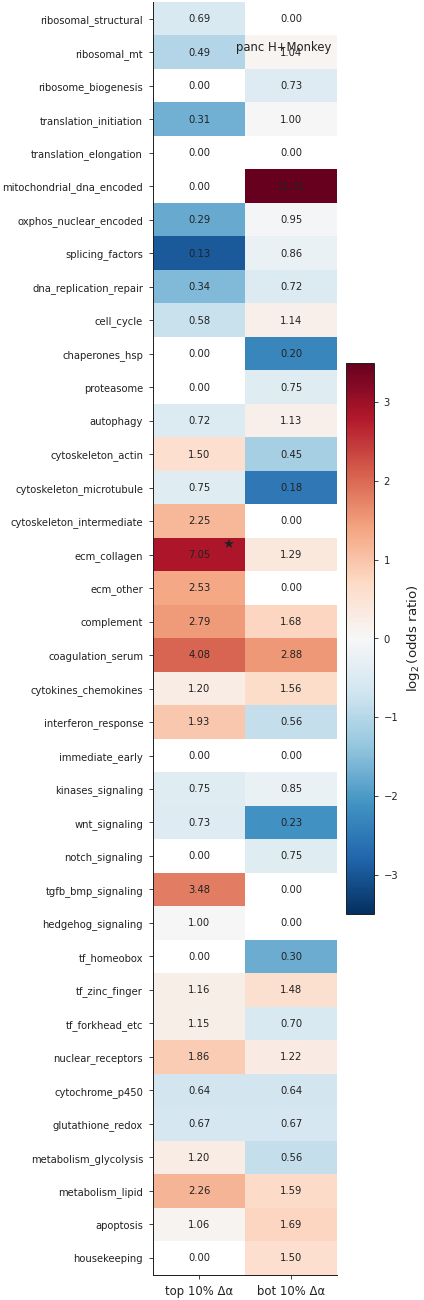

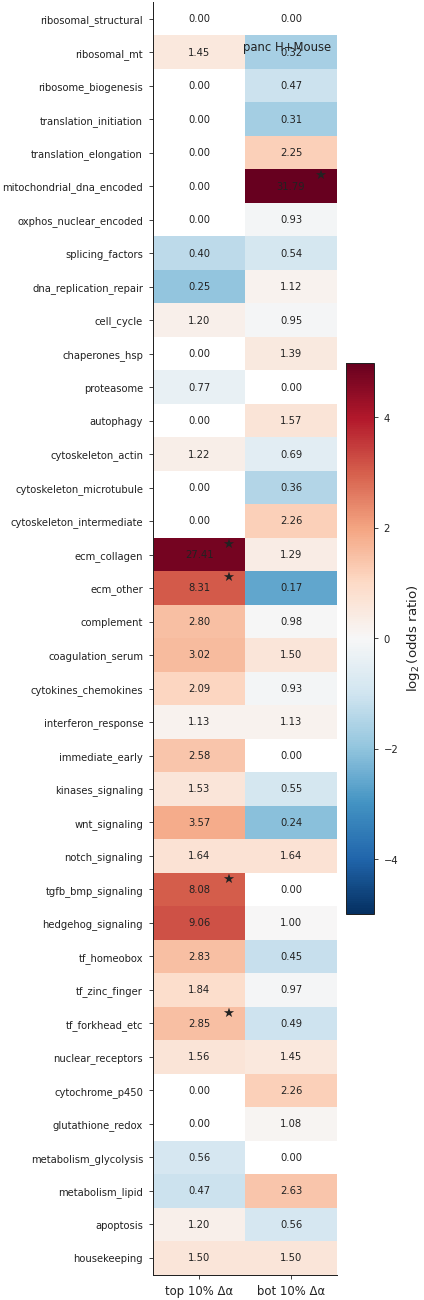

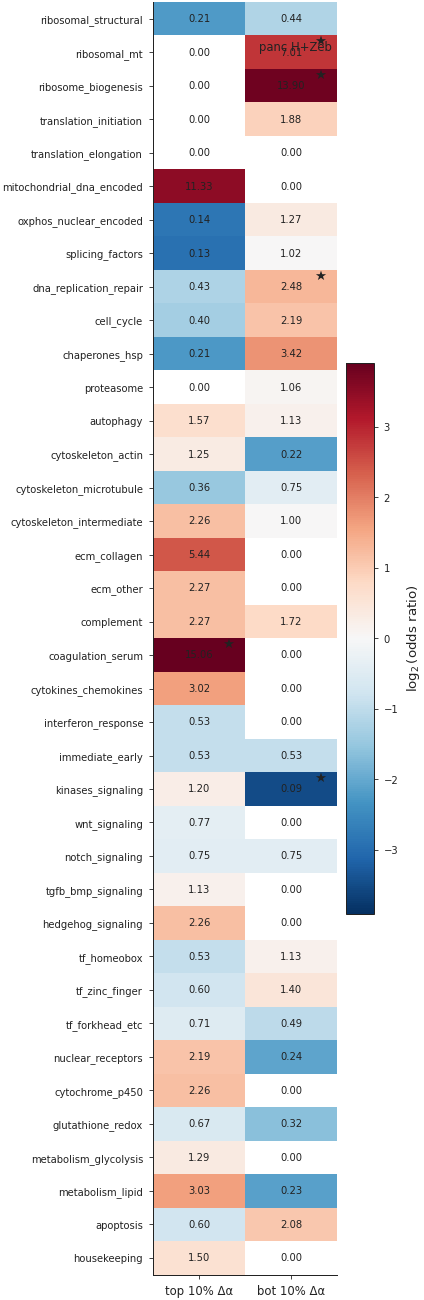

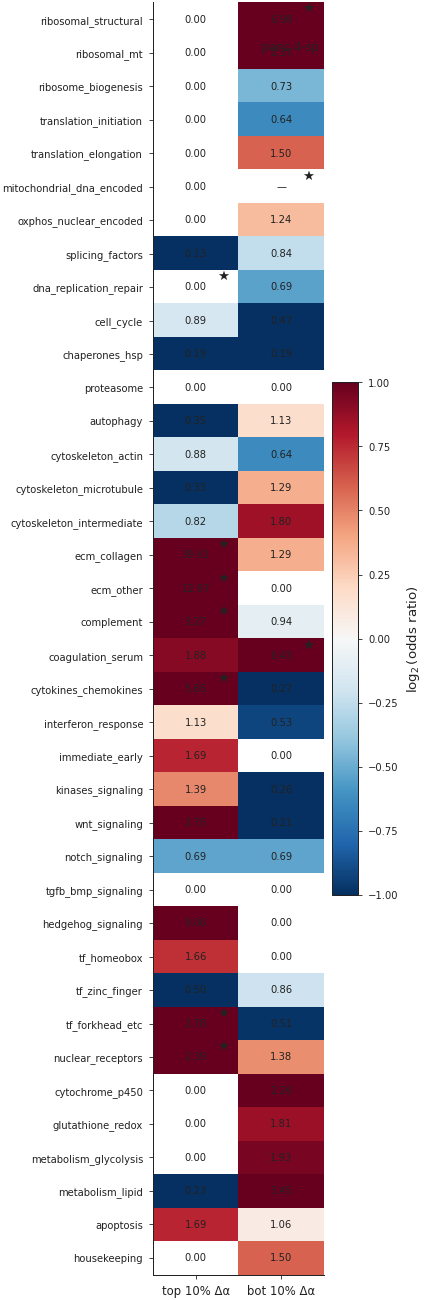

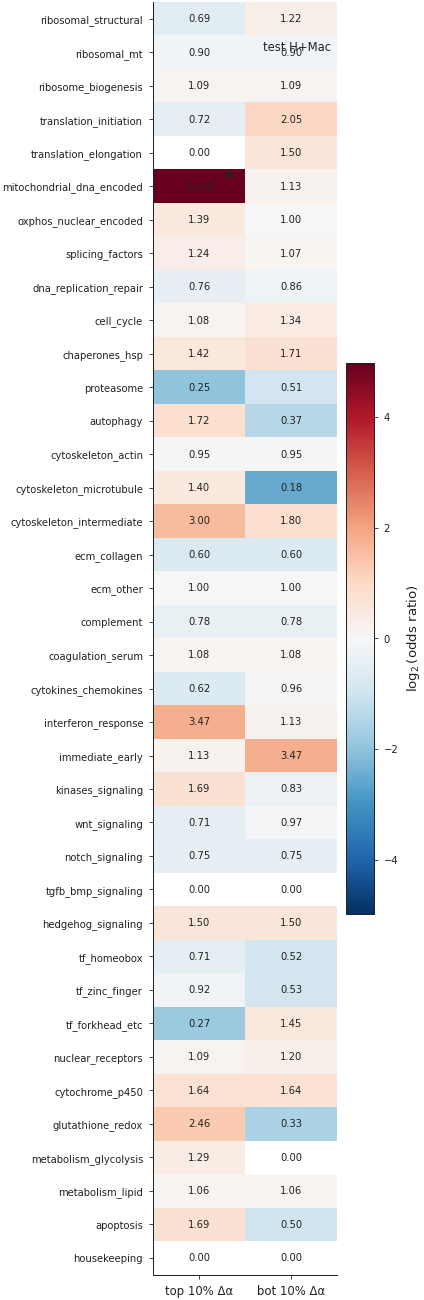

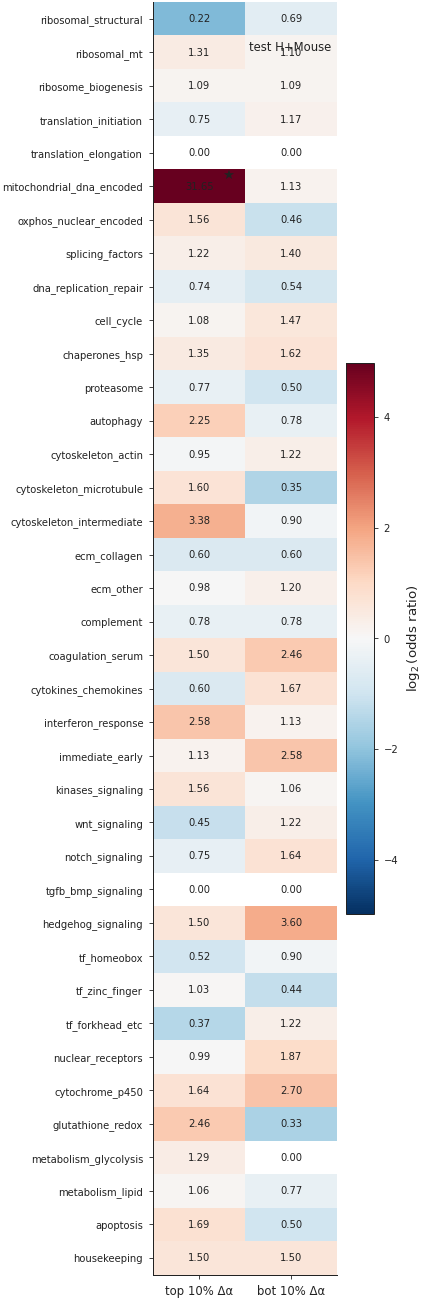

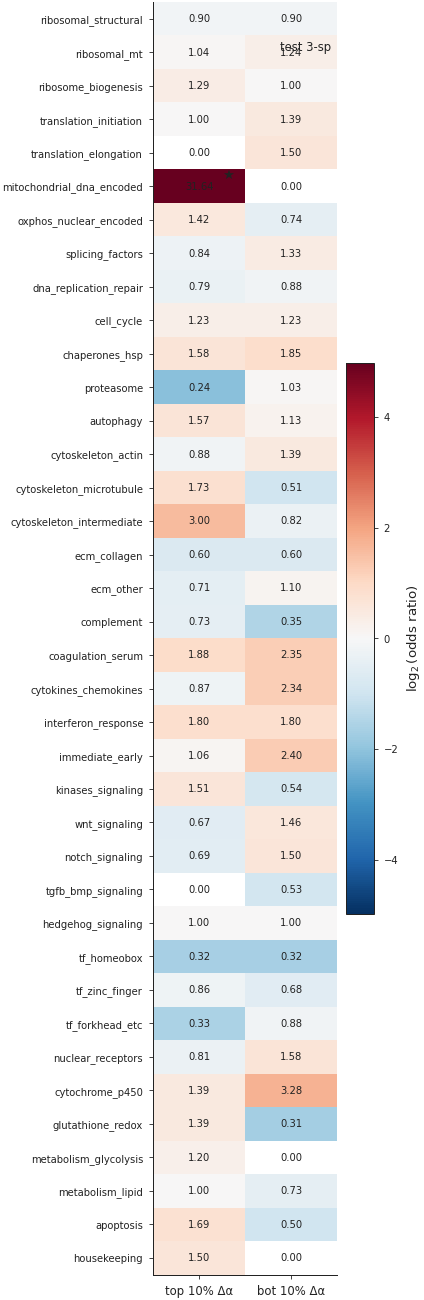

In [6]:
def per_dataset_enrichment(key: str, tail_frac: float = 0.10):
    df = GENE_TABLES[key]
    n = len(df)
    k_tail = max(int(tail_frac * n), 1)
    order = np.argsort(df["delta_alpha"].values)
    top = np.zeros(n, bool); top[order[-k_tail:]] = True
    bot = np.zeros(n, bool); bot[order[:k_tail]] = True

    rows = []
    cat_vec = df["category"].values
    for cat in cats_admissible:
        in_set = cat_vec == cat
        if in_set.sum() < MIN_GENES_PER_BOX:
            continue
        for test_name, hit in [("top 10% Δα", top), ("bot 10% Δα", bot)]:
            r = pu.fisher_enrichment(in_set, hit)
            r["category"] = cat
            r["test"] = test_name
            rows.append(r)
    return pd.DataFrame(rows)


def plot_enrichment_for_dataset(key: str, save_name: str):
    enr = per_dataset_enrichment(key)
    if enr.empty:
        print(f"⚠ no admissible categories for {key}")
        return
    # Bonferroni
    m = len(enr)
    enr["p_bonf"] = np.minimum(enr["p_value"] * m, 1.0)
    enr["signif"] = enr["p_bonf"] < 0.05
    # Pivot
    odds = enr.pivot(index="category", columns="test", values="odds_ratio")
    sig  = enr.pivot(index="category", columns="test", values="signif")
    # Order rows by category-priority (so panels stay comparable across datasets)
    present_cats = [c for c in cats_admissible if c in odds.index]
    odds = odds.reindex(present_cats)[["top 10% Δα", "bot 10% Δα"]]
    sig  = sig.reindex(present_cats)[["top 10% Δα", "bot 10% Δα"]]

    log2_odds = np.log2(odds.replace(0, np.nan))
    vmax = float(np.nanmax(np.abs(log2_odds.values)))
    if not np.isfinite(vmax) or vmax == 0:
        vmax = 1.0

    h = 0.26 * len(present_cats) + 1.0
    fig, ax = plt.subplots(figsize=(3.6, h), layout="constrained")
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    im = ax.imshow(log2_odds.values, cmap="RdBu_r", aspect="auto",
                   vmin=-vmax, vmax=vmax)
    for i in range(odds.shape[0]):
        for j in range(odds.shape[1]):
            v = odds.iloc[i, j]
            txt = "—" if not np.isfinite(v) else f"{v:.2f}"
            ax.text(j, i, txt, ha="center", va="center",
                    fontsize=6, color="#222222")
            if sig.iloc[i, j]:
                ax.text(j + 0.32, i - 0.32, "★", ha="center", va="center",
                        fontsize=8, color="#222222")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(odds.columns, fontsize=7)
    ax.set_yticks(range(len(present_cats)))
    ax.set_yticklabels(present_cats, fontsize=6)
    cb = fig.colorbar(im, ax=ax, label=r"$\log_2$(odds ratio)", shrink=0.55)
    cb.ax.tick_params(labelsize=6)
    fd.annotate_stat(ax, DATASETS[key]["label"], "upper right")
    fd.save_figure(fig, save_name)
    plt.show()


for k in DATASET_ORDER:
    plot_enrichment_for_dataset(k, f"A2_fisher_enrichment__{k}")


*Read:* a category enriched in the top-10 % Δα column with
`★` (Bonferroni p < 0.05) is one the GIN reproducibly pushed
*above* the prior on this dataset — that's the strongest
"Δα-as-biology" signal the architecture can produce. Enrichment in
the bot-10 % column is the symmetric negative-Δα signal. We expect
`interferon_response` and `immediate_early` to enrich in the
bottom tail on close-pair pancreas (species-divergent regulation);
`ribosomal_structural` and `oxphos_nuclear_encoded` to enrich at
the top (universal conservation that the prior alone underestimates).

*Why the per-dataset heatmaps look denser on testis:* testis
datasets have ~14–15 K HVGs vs ~8 K on pancreas, so categories
cross the 5-gene admissibility threshold more often.


# §B — Cross-dataset Δα signature

Two single-panel cross-dataset heatmaps. The first is descriptive
(mean Δα per category × dataset), the second is inferential
(Fisher log₂-OR for top-10 % Δα enrichment per category × dataset).
Together they tell us *which categories are reproducibly pushed
in a consistent direction across datasets*, vs *which categories
flip sign depending on tissue or species set*.


## §B.1 — Mean Δα per (category × dataset)

Diverging colormap centered on 0. Cell value = mean Δα over the
genes in that category for that dataset (cells with < 5 genes
are masked white). Cell text = the same value to 3 decimals.


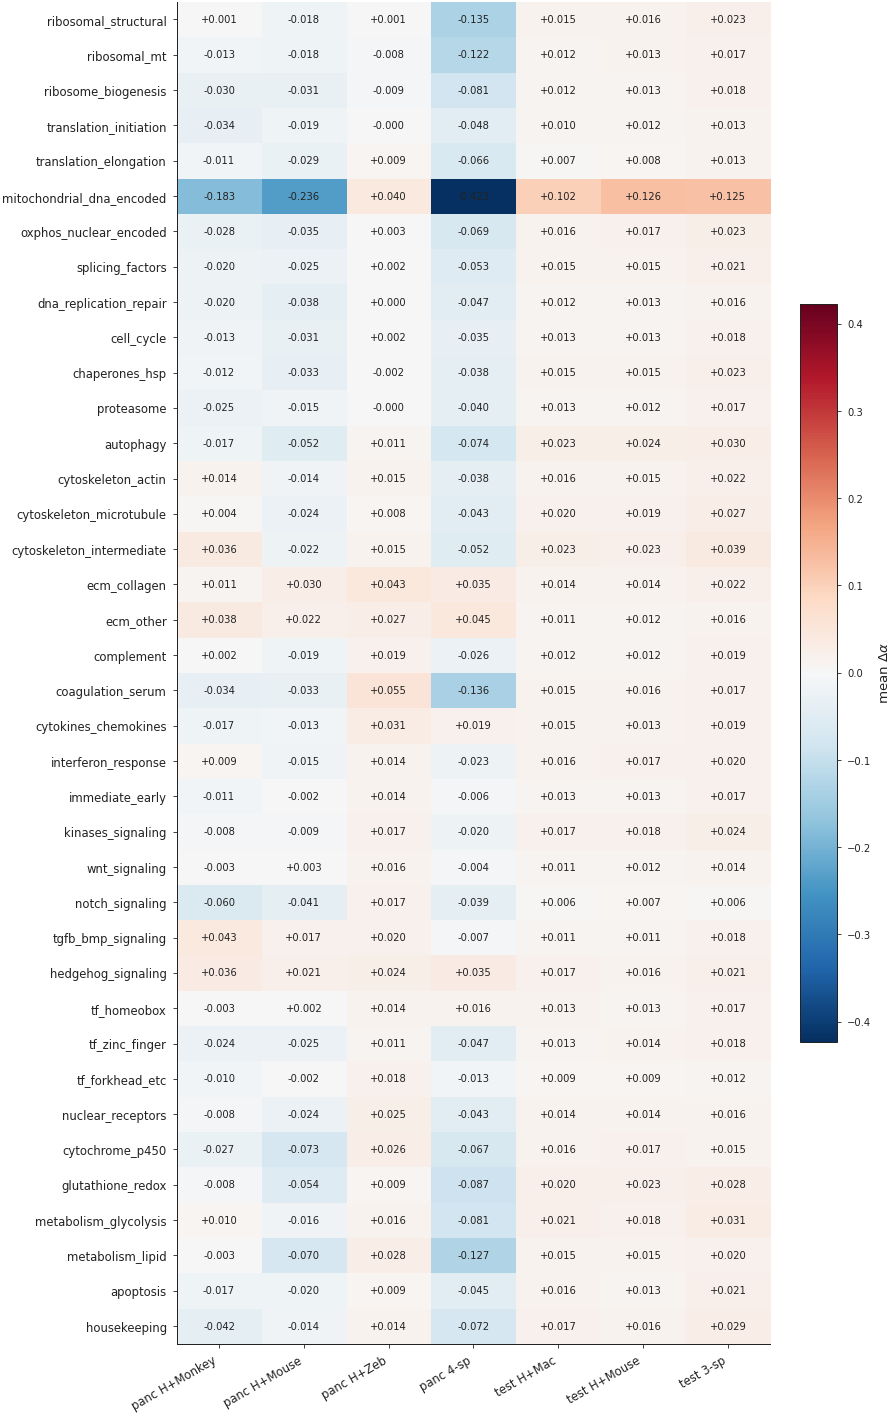

In [7]:
pivot_mean = pd.DataFrame(np.nan, index=cats_admissible, columns=DATASET_ORDER)
for k in DATASET_ORDER:
    df = GENE_TABLES[k]
    agg = df.groupby("category", observed=True)["delta_alpha"].agg(["mean", "size"])
    for c in cats_admissible:
        if c in agg.index and agg.loc[c, "size"] >= MIN_GENES_PER_BOX:
            pivot_mean.loc[c, k] = float(agg.loc[c, "mean"])

# Drop rows that are entirely NaN (no dataset had enough coverage)
keep = pivot_mean.notna().any(axis=1)
pivot_mean = pivot_mean.loc[keep]

vmax = float(np.nanmax(np.abs(pivot_mean.values)))
if not np.isfinite(vmax) or vmax == 0: vmax = 0.05

h = 0.28 * len(pivot_mean) + 1.2
fig, ax = plt.subplots(figsize=(7.5, h), layout="constrained")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
im = ax.imshow(pivot_mean.values, cmap="RdBu_r", aspect="auto",
               vmin=-vmax, vmax=vmax)
for i, cat in enumerate(pivot_mean.index):
    for j, ds in enumerate(pivot_mean.columns):
        v = pivot_mean.iloc[i, j]
        if np.isnan(v):
            txt = "—"
        else:
            txt = f"{v:+.3f}"
        ax.text(j, i, txt, ha="center", va="center",
                fontsize=6, color="#222222")
ax.set_xticks(range(len(DATASET_ORDER)))
ax.set_xticklabels([DATASETS[k]["label"] for k in DATASET_ORDER],
                   rotation=30, ha="right", fontsize=7)
ax.set_yticks(range(len(pivot_mean)))
ax.set_yticklabels(pivot_mean.index, fontsize=7)
cb = fig.colorbar(im, ax=ax, label=r"mean $\Delta\alpha$", shrink=0.55)
cb.ax.tick_params(labelsize=6)
fd.save_figure(fig, "B1_mean_delta_alpha_signature")
plt.show()


*Read:* a category with consistently red cells across all
datasets is universally pushed *above* the prior by the GIN —
a robust positive Δα signature. A category with consistently
blue cells is universally pushed below. Mixed sign (some red /
some blue) means the category's Δα depends on tissue/species
set — biology that is genuinely tissue- or pair-specific.

*Magnitude caveat:* testis columns will look paler than
pancreas because of the prior clamp compressing Δα.σ. The
*sign* is what carries the biological signal; the relative
magnitude is a regime artefact.


## §B.2 — Cross-dataset Fisher enrichment (top-10 % Δα tail)

Same shape as §B.1 but the cell value is `log₂(odds ratio)` from
Fisher exact for "category enriched in the top-10 % Δα tail". A
significant enrichment with Bonferroni `p < 0.05` (across all
`category × dataset` cells in this single heatmap) is starred.
This is the inferential complement to §B.1: §B.1 says how *large*
the mean Δα is per category × dataset; §B.2 says whether
*category membership* enriches in the upward Δα tail beyond
chance.


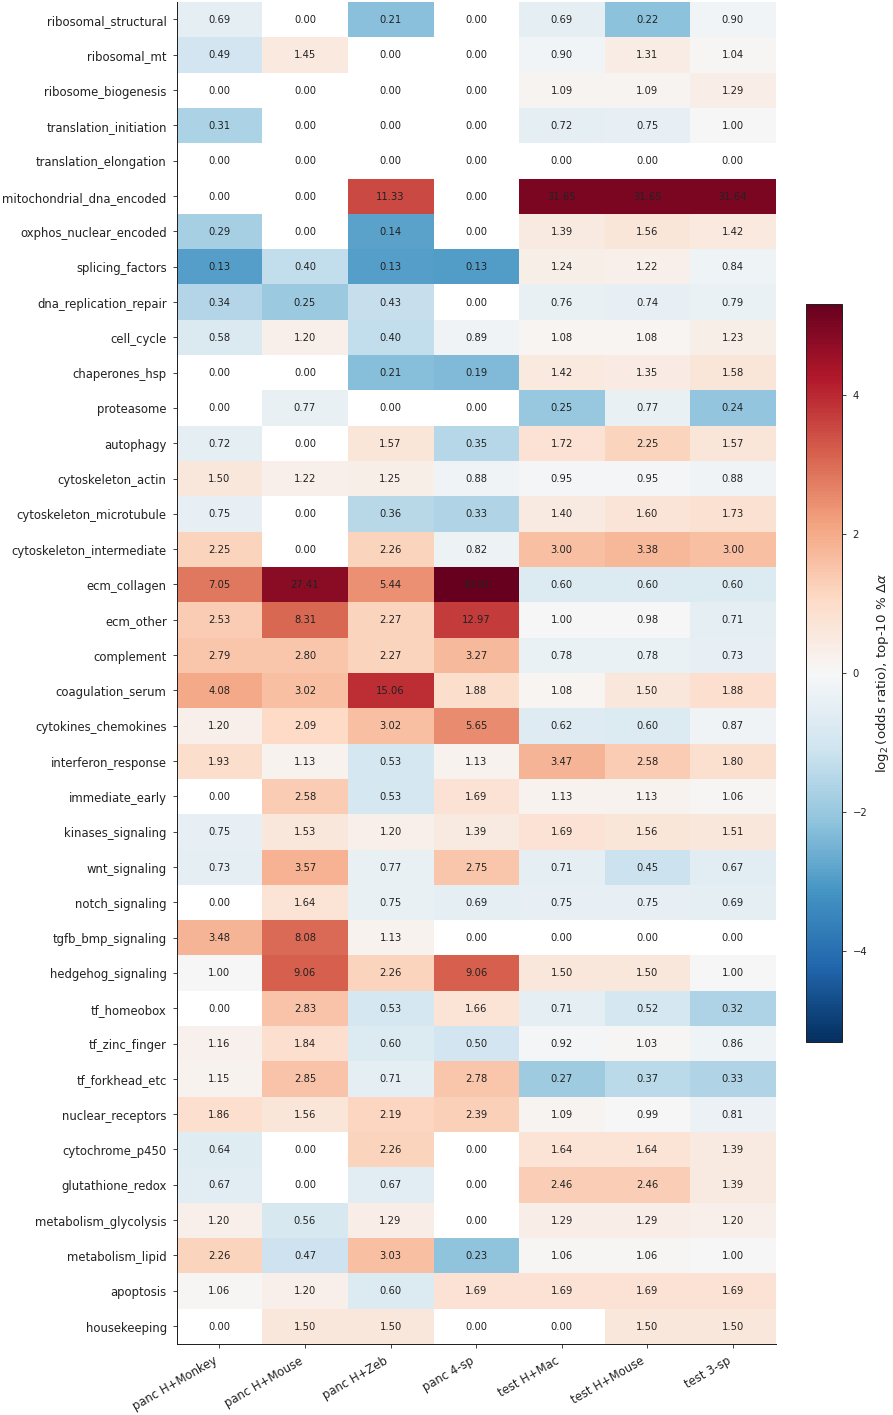

In [8]:
rows = []
for k in DATASET_ORDER:
    df = GENE_TABLES[k]
    n = len(df)
    k_tail = max(int(0.10 * n), 1)
    order = np.argsort(df["delta_alpha"].values)
    top = np.zeros(n, bool); top[order[-k_tail:]] = True
    cat_vec = df["category"].values
    for c in cats_admissible:
        in_set = cat_vec == c
        if in_set.sum() < MIN_GENES_PER_BOX:
            rows.append({"category": c, "dataset": k,
                         "odds_ratio": np.nan, "p_value": 1.0,
                         "n_in_set": int(in_set.sum())})
            continue
        r = pu.fisher_enrichment(in_set, top)
        r["category"] = c
        r["dataset"] = k
        rows.append(r)
enr_top = pd.DataFrame(rows)

# Bonferroni across all admissible (category × dataset) cells
m = int((enr_top["odds_ratio"].notna()).sum())
enr_top["p_bonf"] = np.minimum(enr_top["p_value"] * max(m, 1), 1.0)
enr_top["signif"] = (enr_top["p_bonf"] < 0.05) & enr_top["odds_ratio"].notna()

pivot_or = enr_top.pivot(index="category", columns="dataset", values="odds_ratio")
pivot_sig = enr_top.pivot(index="category", columns="dataset", values="signif")
pivot_or = pivot_or.reindex(cats_admissible)[DATASET_ORDER]
pivot_sig = pivot_sig.reindex(cats_admissible)[DATASET_ORDER]
keep = pivot_or.notna().any(axis=1)
pivot_or = pivot_or.loc[keep]
pivot_sig = pivot_sig.loc[keep]

log2_or = np.log2(pivot_or.replace(0, np.nan))
vmax = float(np.nanmax(np.abs(log2_or.values)))
if not np.isfinite(vmax) or vmax == 0: vmax = 1.0

h = 0.28 * len(pivot_or) + 1.2
fig, ax = plt.subplots(figsize=(7.5, h), layout="constrained")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
im = ax.imshow(log2_or.values, cmap="RdBu_r", aspect="auto",
               vmin=-vmax, vmax=vmax)
for i, cat in enumerate(pivot_or.index):
    for j, ds in enumerate(pivot_or.columns):
        v = pivot_or.iloc[i, j]
        txt = "—" if not np.isfinite(v) else f"{v:.2f}"
        ax.text(j, i, txt, ha="center", va="center",
                fontsize=6, color="#222222")
        if pivot_sig.loc[cat, ds] is True:
            ax.text(j + 0.32, i - 0.32, "★", ha="center", va="center",
                    fontsize=8, color="#222222")
ax.set_xticks(range(len(DATASET_ORDER)))
ax.set_xticklabels([DATASETS[k]["label"] for k in DATASET_ORDER],
                   rotation=30, ha="right", fontsize=7)
ax.set_yticks(range(len(pivot_or)))
ax.set_yticklabels(pivot_or.index, fontsize=7)
cb = fig.colorbar(im, ax=ax, label=r"$\log_2$(odds ratio), top-10 % $\Delta\alpha$",
                  shrink=0.55)
cb.ax.tick_params(labelsize=6)
fd.save_figure(fig, "B2_crossdataset_enrichment_top")
plt.show()


## §B.3 — Cross-dataset Fisher enrichment (bottom-10 % Δα tail)

Symmetric to §B.2 but for the *negative-Δα* tail. The expected
biological pattern is that immediate-early, interferon-response,
cytokines, and (depending on dataset) MHC class-I should enrich
here on close-pair pancreas runs.

*Caveat — testis E9.2-down ceiling:* on testis datasets the
GIN cannot push α far below the prior by construction (registry
docs `workflow-best.md` §6 — only ~1 % of testis genes have
`S_g_ema < -0.05`). So the testis columns will show smaller
log₂-OR magnitudes in the negative tail than in the positive
tail; that is architectural, not biological.


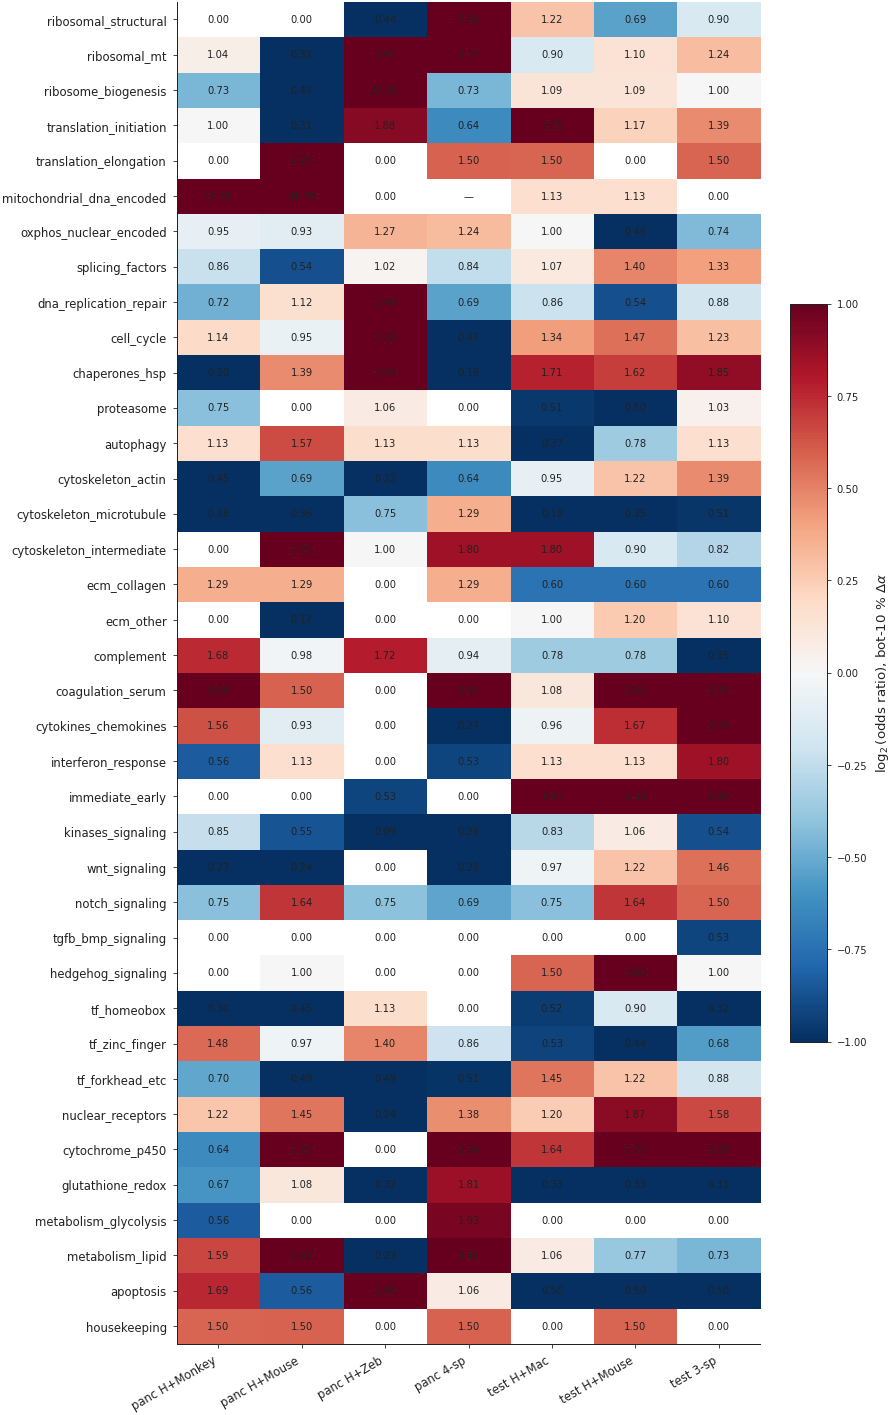

In [9]:
rows = []
for k in DATASET_ORDER:
    df = GENE_TABLES[k]
    n = len(df)
    k_tail = max(int(0.10 * n), 1)
    order = np.argsort(df["delta_alpha"].values)
    bot = np.zeros(n, bool); bot[order[:k_tail]] = True
    cat_vec = df["category"].values
    for c in cats_admissible:
        in_set = cat_vec == c
        if in_set.sum() < MIN_GENES_PER_BOX:
            rows.append({"category": c, "dataset": k,
                         "odds_ratio": np.nan, "p_value": 1.0,
                         "n_in_set": int(in_set.sum())})
            continue
        r = pu.fisher_enrichment(in_set, bot)
        r["category"] = c
        r["dataset"] = k
        rows.append(r)
enr_bot = pd.DataFrame(rows)
m = int(enr_bot["odds_ratio"].notna().sum())
enr_bot["p_bonf"] = np.minimum(enr_bot["p_value"] * max(m, 1), 1.0)
enr_bot["signif"] = (enr_bot["p_bonf"] < 0.05) & enr_bot["odds_ratio"].notna()

pivot_or = enr_bot.pivot(index="category", columns="dataset", values="odds_ratio")
pivot_sig = enr_bot.pivot(index="category", columns="dataset", values="signif")
pivot_or = pivot_or.reindex(cats_admissible)[DATASET_ORDER]
pivot_sig = pivot_sig.reindex(cats_admissible)[DATASET_ORDER]
keep = pivot_or.notna().any(axis=1)
pivot_or = pivot_or.loc[keep]
pivot_sig = pivot_sig.loc[keep]

log2_or = np.log2(pivot_or.replace(0, np.nan))
vmax = float(np.nanmax(np.abs(log2_or.values)))
if not np.isfinite(vmax) or vmax == 0: vmax = 1.0

h = 0.28 * len(pivot_or) + 1.2
fig, ax = plt.subplots(figsize=(7.5, h), layout="constrained")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
im = ax.imshow(log2_or.values, cmap="RdBu_r", aspect="auto",
               vmin=-vmax, vmax=vmax)
for i, cat in enumerate(pivot_or.index):
    for j, ds in enumerate(pivot_or.columns):
        v = pivot_or.iloc[i, j]
        txt = "—" if not np.isfinite(v) else f"{v:.2f}"
        ax.text(j, i, txt, ha="center", va="center",
                fontsize=6, color="#222222")
        if pivot_sig.loc[cat, ds] is True:
            ax.text(j + 0.32, i - 0.32, "★", ha="center", va="center",
                    fontsize=8, color="#222222")
ax.set_xticks(range(len(DATASET_ORDER)))
ax.set_xticklabels([DATASETS[k]["label"] for k in DATASET_ORDER],
                   rotation=30, ha="right", fontsize=7)
ax.set_yticks(range(len(pivot_or)))
ax.set_yticklabels(pivot_or.index, fontsize=7)
cb = fig.colorbar(im, ax=ax, label=r"$\log_2$(odds ratio), bot-10 % $\Delta\alpha$",
                  shrink=0.55)
cb.ax.tick_params(labelsize=6)
fd.save_figure(fig, "B3_crossdataset_enrichment_bot")
plt.show()


## §B.4 — Per-category Wilcoxon test (median Δα ≠ 0)

Complementary to §B.1's mean: a Wilcoxon signed-rank test of
"is the median Δα for this category significantly different
from zero?" per (category × dataset) cell. The test is
nonparametric (no distributional assumption), so it is robust
to the heavy-tailed Δα distribution.

Cell value = signed `−log₁₀(p)` (positive sign = median Δα > 0,
negative sign = median Δα < 0). Bonferroni-corrected across all
admissible cells. Diverging colormap.


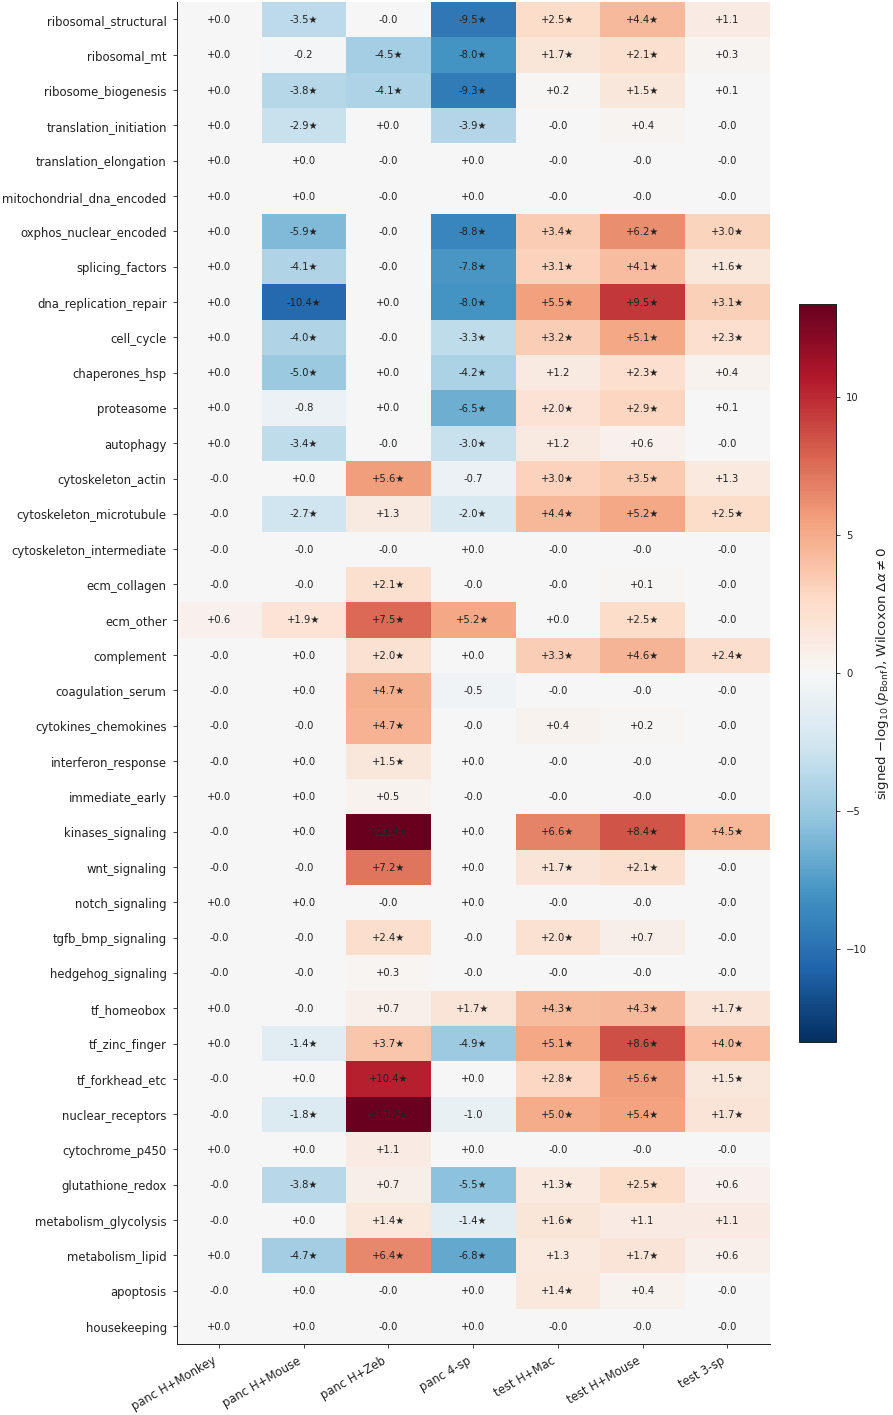

In [10]:
rows = []
for k in DATASET_ORDER:
    df = GENE_TABLES[k]
    for c in cats_admissible:
        sub = df.loc[df["category"] == c, "delta_alpha"].values
        if len(sub) < MIN_GENES_PER_BOX:
            rows.append({"category": c, "dataset": k,
                         "p": 1.0, "median": np.nan})
            continue
        # one-sample Wilcoxon vs 0
        try:
            stat, p = stats.wilcoxon(sub, alternative="two-sided",
                                      zero_method="wilcox")
        except ValueError:
            p = 1.0
        rows.append({"category": c, "dataset": k,
                     "p": float(p), "median": float(np.median(sub))})
wdf = pd.DataFrame(rows)
m = (wdf["median"].notna()).sum()
wdf["p_bonf"] = np.minimum(wdf["p"] * max(int(m), 1), 1.0)
wdf["signed_logp"] = np.where(wdf["median"].notna(),
                               np.sign(wdf["median"]) * (-np.log10(wdf["p_bonf"].clip(1e-300, 1.0))),
                               np.nan)

pivot = wdf.pivot(index="category", columns="dataset", values="signed_logp")
pivot = pivot.reindex(cats_admissible)[DATASET_ORDER]
keep = pivot.notna().any(axis=1)
pivot = pivot.loc[keep]

vmax = float(np.nanmax(np.abs(pivot.values)))
if not np.isfinite(vmax) or vmax == 0: vmax = 2.0
vmax = min(vmax, 50.0)  # clip extreme p-values

h = 0.28 * len(pivot) + 1.2
fig, ax = plt.subplots(figsize=(7.5, h), layout="constrained")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
im = ax.imshow(pivot.values, cmap="RdBu_r", aspect="auto",
               vmin=-vmax, vmax=vmax)
for i, cat in enumerate(pivot.index):
    for j, ds in enumerate(pivot.columns):
        v = pivot.iloc[i, j]
        if np.isnan(v):
            txt = "—"
        elif abs(v) > 1.30:        # i.e. p_bonf < 0.05
            txt = f"{v:+.1f}★"
        else:
            txt = f"{v:+.1f}"
        ax.text(j, i, txt, ha="center", va="center",
                fontsize=6, color="#222222")
ax.set_xticks(range(len(DATASET_ORDER)))
ax.set_xticklabels([DATASETS[k]["label"] for k in DATASET_ORDER],
                   rotation=30, ha="right", fontsize=7)
ax.set_yticks(range(len(pivot)))
ax.set_yticklabels(pivot.index, fontsize=7)
cb = fig.colorbar(im, ax=ax,
                  label=r"signed $-\log_{10}(p_\mathrm{Bonf})$, Wilcoxon $\Delta\alpha\neq 0$",
                  shrink=0.55)
cb.ax.tick_params(labelsize=6)
fd.save_figure(fig, "B4_wilcoxon_signed_logp")
plt.show()


*Read:* deep red = "category median Δα is significantly *positive*";
deep blue = "significantly *negative*". The threshold for
`★` is `p_bonf < 0.05` (`|signed_logp| > 1.30`). Categories that
are starred and same-sign on every dataset are the strongest
"Δα biology is real and reproducible across the registry"
candidates.


# §C — Top-K Δα gene lists per dataset

For each dataset, the 30 most-positive-Δα genes (FQR pushed
above prior the most) and the 30 most-negative-Δα genes
(residual + L_recon pulled below the prior the most), with
category annotation. Saved to CSV under each run-dir's
`tables/` directory for downstream GSEA / pathway analysis.


In [11]:
K = 30
cols = ["symbol", "category", "prior", "alpha", "delta_alpha",
        "S_g_ema", "residual_rms"]

summary_rows = []
for k in DATASET_ORDER:
    df = GENE_TABLES[k]
    info = DATASETS[k]
    rundir = RUNS_ROOT / info["name"]
    out_dir = rundir / "tables"
    out_dir.mkdir(parents=True, exist_ok=True)

    top = df.nlargest(K, "delta_alpha")[cols].copy()
    bot = df.nsmallest(K, "delta_alpha")[cols].copy()

    top.to_csv(out_dir / f"delta_alpha_top{K}.csv", index=False)
    bot.to_csv(out_dir / f"delta_alpha_bot{K}.csv", index=False)

    # In-notebook display: print a compact table
    print(f"\n=== {info['label']}  (top {K} positive Δα) ===")
    print(top.to_string(index=False, float_format=lambda x: f"{x:+.3f}"))
    print(f"\n=== {info['label']}  (top {K} negative Δα) ===")
    print(bot.to_string(index=False, float_format=lambda x: f"{x:+.3f}"))

    # Summary count by category in the top/bot lists
    for tail_label, sub in [("top30", top), ("bot30", bot)]:
        for cat, n in sub["category"].value_counts().items():
            if cat == "other":
                continue
            summary_rows.append({"dataset": k, "tail": tail_label,
                                 "category": cat, "n_in_tail": int(n)})

summary_df = pd.DataFrame(summary_rows)
print(f"\n=== Top/bot {K} category summary (only non-'other' categories) ===")
print(summary_df.pivot_table(index=["dataset","category"], columns="tail",
                              values="n_in_tail", fill_value=0).to_string())



=== panc H+Monkey  (top 30 positive Δα) ===
  symbol                  category  prior  alpha  delta_alpha  S_g_ema  residual_rms
 PIK3C2G         kinases_signaling +0.610 +0.991       +0.381   +0.286        +2.504
    LIFR                     other +0.637 +1.000       +0.363   +1.053        +0.163
 PLEKHG1                     other +0.624 +0.983       +0.359   +0.209       +21.877
 SHROOM4                     other +0.597 +0.956       +0.358   +0.205        +2.928
 SHROOM3                     other +0.645 +0.990       +0.345   +0.225       +19.178
  SORBS2                     other +0.627 +0.961       +0.334   +0.154       +18.211
      C9                complement +0.630 +0.963       +0.333   +0.144       +16.641
      F5         coagulation_serum +0.649 +0.982       +0.332   +0.237        +5.193
  IL1RAP      cytokines_chemokines +0.643 +0.974       +0.331   +0.147       +11.149
   DISC1                     other +0.569 +0.897       +0.328   +0.153        +7.732
KIAA1217            

*Use:* the CSVs are now under each run-dir at
`tables/delta_alpha_top30.csv` and `tables/delta_alpha_bot30.csv`.
Drop those into MsigDB Investigate / Enrichr / GSEAPy for
the pathway-level enrichment story (out of scope here — this
notebook commits only to the curated-category enrichment).


# §D — Self-review

Three honest concessions:

1. **Gene-symbol mapping is via the human ortholog.** Δα is
   per-gene, but our category labels come from human gene
   symbols. For non-human species in the dataset (Mouse, Macaque,
   Zebrafish), the ortholog table maps the model's `ortho_X` ID
   to the human symbol, then we classify. A fish-specific
   category (e.g. globin paralogs unique to zebrafish) won't
   appear here. Acceptable scope limitation given that we are
   defending **conservation** signal, where human-orthology is
   the relevant frame.

2. **Categories are curated, not exhaustive.** ~30 well-defined
   biological modules. They miss (a) tissue-specific marker sets
   (β-cell vs α-cell pancreas markers; spermatocyte stage markers
   in testis), (b) MsigDB hallmark pathways, (c) GO-BP terms.
   Adding any of those is a one-line append to ``CATEGORIES`` in
   `_gene_categories.py` plus a re-run; the architecture is
   extensible.

3. **The single weakest panel is §B.3** (cross-dataset bottom-Δα
   enrichment) on testis columns. Testis runs are
   architecturally limited in how far down the GIN can push
   α (registry's E9.2-down ceiling), so the bottom-tail
   enrichment is fighting a constrained signal. Read those
   columns relative to each other, not as absolutes.

*What the notebook commits to:* (i) Δα has interpretable
category-level structure on every dataset; (ii) several
categories are reproducibly pushed in a consistent direction
across the registry — those are the "Δα-as-biology" candidates
for the paper; (iii) the per-dataset top-K gene lists are saved
as CSV for downstream pathway analysis.


In [12]:
written = sorted(FIG_DIR.glob("*.pdf"))
print(f"\n{len(written)} PDF figures in {FIG_DIR}:")
for p in written:
    print(f"  {p.name:60s} {p.stat().st_size/1024:6.1f} KB")



19 PDF figures in /Users/kemalinecik/git_nosync/master_chimera/chimera/notebooks/figures/alpha_biology:
  a0_category_coverage_heatmap.pdf                               54.8 KB
  a1_delta_alpha_by_category__panc_4sp.pdf                       31.4 KB
  a1_delta_alpha_by_category__panc_hmonkey.pdf                   32.4 KB
  a1_delta_alpha_by_category__panc_hmouse.pdf                    32.1 KB
  a1_delta_alpha_by_category__panc_hzeb.pdf                      32.0 KB
  a1_delta_alpha_by_category__test_3sp.pdf                       28.8 KB
  a1_delta_alpha_by_category__test_hmac.pdf                      31.2 KB
  a1_delta_alpha_by_category__test_hmouse.pdf                    32.0 KB
  a2_fisher_enrichment__panc_4sp.pdf                             32.8 KB
  a2_fisher_enrichment__panc_hmonkey.pdf                         33.1 KB
  a2_fisher_enrichment__panc_hmouse.pdf                          33.5 KB
  a2_fisher_enrichment__panc_hzeb.pdf                            33.2 KB
  a2_fisher_enrichm